In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, differential_evolution
from lenstronomy.LensModel.lens_model import LensModel
from lenstronomy.LensModel.Solver.lens_equation_solver import LensEquationSolver
from lenstronomy.Util import util
from matplotlib.patches import Ellipse

# ===========================================================================
# 1. LOAD AND TRANSFORM DATA (Right-Handed Coordinate Grid)
# ===========================================================================
c1 = pd.read_csv('cluster1.csv').sort_values('RAcen').reset_index(drop=True)
c2 = pd.read_csv('cluster2.csv').sort_values('RAcen').reset_index(drop=True)
s1 = pd.read_csv('system_1.412.csv')
s2 = pd.read_csv('system_1.407.csv')  # Uses all 6 observed lensed coordinates

ra_ref, dec_ref = 180.162, -1.451

def to_arcsec(ra, dec):
    # Flipped to standard right-handed Cartesian grid (West-is-Right, East-is-Left)
    x = -(ra - ra_ref) * 3600 * np.cos(np.radians(dec_ref))
    y = (dec - dec_ref) * 3600
    return x, y

x_img1, y_img1 = to_arcsec(s1['RA'], s1['DEC'])
x_img2, y_img2 = to_arcsec(s2['RA'], s2['DEC'])

# ===========================================================================
# COSMOLOGY CONFIGURATION (Change parameters here to test alternative universes)
# ===========================================================================
from astropy.cosmology import FlatLambdaCDM, Flatw0waCDM
import astropy.units as u

# Define your cosmology. You can vary these to see the impact on predicted images:
# - H0: Hubble constant (km/s/Mpc) [standard value is 70.0]
# - Om0: Dimensionless matter density parameter at z=0 [standard value is 0.3]
# - Ob0: Baryonic matter density parameter [standard value is 0.05]
custom_cosmo = Flatw0waCDM(H0=66.74, Om0=0.3191, Tcmb0=2.7255, Neff=3.046, Ob0=0.04897, m_nu=[0.0, 0.0, 0.06] * u.eV, w0=-0.752, wa=-0.86)

# ===========================================================================
# 2. SETUP MULTI-PLANE LENS MODEL (SERSICs + DM Halos + External Shears)
# ===========================================================================
# We model 22 elliptical Sersics, 3 elliptical NFW halos (two for Cluster 1, one for Cluster 2), and 2 external shears
lens_model_list = ['SERSIC_ELLIPSE_POTENTIAL'] * 22 + ['NFW_ELLIPSE_POTENTIAL'] * 3 + ['SHEAR'] * 2

# Project all components onto their respective cluster planes:
# Galaxies share cluster planes, NFW halos are at [z1, z1, z2], shears are at [z1, z2]
lens_redshift_list = [0.268] * len(c1) + [0.327] * len(c2) + [0.268, 0.268, 0.327] + [0.268, 0.327]
# We pass the custom cosmology object into both multi-plane lens models
lensModel_s1 = LensModel(lens_model_list=lens_model_list, lens_redshift_list=lens_redshift_list, multi_plane=True, z_source=1.412,cosmo=custom_cosmo)
# S2 model represents the background source at z=1.407
lensModel_s2 = LensModel(lens_model_list=lens_model_list, lens_redshift_list=lens_redshift_list, multi_plane=True, z_source=1.407,cosmo=custom_cosmo)

rs1, rs2 = 13.56, 9.23   # Fixed scale radii of dark matter halos from cosmological masses

# Pre-calculate NFW coordinates centered on the three cluster cores
xc_n1_a, yc_n1_a = to_arcsec(c1.loc[2, 'RAcen'], c1.loc[2, 'Deccen'])   # Cluster 1 Core A (Galaxy 03 center)
xc_n1_b, yc_n1_b = to_arcsec(c1.loc[8, 'RAcen'], c1.loc[8, 'Deccen'])   # Cluster 1 Core B (Galaxy 09 center)
xc_n2, yc_n2 = to_arcsec(c2.loc[7, 'RAcen'], c2.loc[7, 'Deccen'])       # Cluster 2 Core (Galaxy 15 center)

def get_kwargs_lens(params):
    (
        k_m1, k_m2, k_m3, k_b1, k_b2,              # Sersic amplitudes (5)
        alpha_rs1a, alpha_rs1b, alpha_rs2,         # NFW halo amplitudes (3)
        e1_n1a, e2_n1a, e1_n1b, e2_n1b, e1_n2, e2_n2,# NFW halo ellipticities (6)
        g1_s1, g2_s1, g1_s2, g2_s2,                # External shears (4)
        e1_m1, e2_m1, e1_m2, e2_m2, e1_m3, e2_m3   # Massive galaxy ellipticities (6)
    ) = params
    
    kwargs_lens = []
    
    # Plane 1: Cluster 1 Sersics (z=0.268)
    for i, row in c1.iterrows():
        x, y = to_arcsec(row['RAcen'], row['Deccen'])
        if i == 2:
            kwargs_lens.append({'k_eff': k_m1, 'R_sersic': 3.5, 'n_sersic': 4.0, 'e1': e1_m1, 'e2': e2_m1, 'center_x': x, 'center_y': y})
        elif i == 8:
            kwargs_lens.append({'k_eff': k_m2, 'R_sersic': 3.5, 'n_sersic': 4.0, 'e1': e1_m2, 'e2': e2_m2, 'center_x': x, 'center_y': y})
        else:
            kwargs_lens.append({'k_eff': k_b1, 'R_sersic': 0.8, 'n_sersic': 4.0, 'e1': 0.0, 'e2': 0.0, 'center_x': x, 'center_y': y})
            
    # Plane 2: Cluster 2 Sersics (z=0.327)
    for i, row in c2.iterrows():
        x, y = to_arcsec(row['RAcen'], row['Deccen'])
        if i == 7:
            kwargs_lens.append({'k_eff': k_m3, 'R_sersic': 3.0, 'n_sersic': 4.0, 'e1': e1_m3, 'e2': e2_m3, 'center_x': x, 'center_y': y})
        else:
            kwargs_lens.append({'k_eff': k_b2, 'R_sersic': 0.6, 'n_sersic': 4.0, 'e1': 0.0, 'e2': 0.0, 'center_x': x, 'center_y': y})
            
    # Appended Cluster 1 smooth dark matter halo A (z=0.268, centered on Galaxy 03)
    kwargs_lens.append({'Rs': rs1, 'alpha_Rs': alpha_rs1a, 'e1': e1_n1a, 'e2': e2_n1a, 'center_x': xc_n1_a, 'center_y': yc_n1_a})
    
    # Appended Cluster 1 smooth dark matter halo B (z=0.268, centered on Galaxy 09)
    kwargs_lens.append({'Rs': rs1, 'alpha_Rs': alpha_rs1b, 'e1': e1_n1b, 'e2': e2_n1b, 'center_x': xc_n1_b, 'center_y': yc_n1_b})
    
    # Appended Cluster 2 smooth dark matter halo (z=0.327, centered on Galaxy 15)
    kwargs_lens.append({'Rs': rs2, 'alpha_Rs': alpha_rs2, 'e1': e1_n2, 'e2': e2_n2, 'center_x': xc_n2, 'center_y': yc_n2})
    
    # External Shear on Plane 1 (z=0.268) centered on Halo A
    kwargs_lens.append({'gamma1': g1_s1, 'gamma2': g2_s1, 'ra_0': xc_n1_a, 'dec_0': yc_n1_a})
    
    # External Shear on Plane 2 (z=0.327) centered on Halo C
    kwargs_lens.append({'gamma1': g1_s2, 'gamma2': g2_s2, 'ra_0': xc_n2, 'dec_0': yc_n2})
    
    return kwargs_lens

# ===========================================================================
# 3. OBJECTIVE FUNCTION (Minimize Coordinate Spread)
# ===========================================================================
sigma_img = 0.004

def objective(params):
    # 1. Vectorized check: Ensure the first 8 physical mass/potential amplitudes are strictly positive
    if np.any(params[:8] <= 0):
        return 1e10
        
    # 2. Vectorized check: Keep ellipticity parameters (indices 8-13 and 18-23) within physical boundaries (|e| <= 0.8)
    if np.any(np.abs(params[8:14]) > 0.8) or np.any(np.abs(params[18:]) > 0.8):
        return 1e10
        
    # 3. Vectorized check: Keep external shear parameters (indices 14-17) within physical tidal boundaries (|g| <= 0.4)
    if np.any(np.abs(params[14:18]) > 0.4):
        return 1e10
        
    kwargs_lens = get_kwargs_lens(params)
    src1_ra, src1_dec = lensModel_s1.ray_shooting(x_img1, y_img1, kwargs_lens)
    src2_ra, src2_dec = lensModel_s2.ray_shooting(x_img2, y_img2, kwargs_lens)
    
    chi2_1 = (np.sum((src1_ra - np.mean(src1_ra))**2) + np.sum((src1_dec - np.mean(src1_dec))**2)) / (sigma_img**2)
    chi2_2 = (np.sum((src2_ra - np.mean(src2_ra))**2) + np.sum((src2_dec - np.mean(src2_dec))**2)) / (sigma_img**2)
    
    return 0.5 * (chi2_1 + chi2_2)

# ===========================================================================
# 4. TWO-STAGE GLOBAL + LOCAL OPTIMIZATION (Differential Evolution + BFGS)
# ===========================================================================
# Widened bounds to prevent parameter pinning at the edges
# Expanded ONLY the bounds for parameters that were pinned/near the edges to avoid local minima
bounds = [
    (0.1, 5.0),     # k_m1: Cluster 1 Massive 1
    (0.1, 5.0),     # k_m2: Cluster 1 Massive 2
    (0.1, 5.0),     # k_m3: Cluster 2 Massive
    (0.01, 2.0),    # k_b1: Cluster 1 Standards
    (0.01, 2.0),    # k_b2: Cluster 2 Standards
    (0.01, 10.5),   # alpha_rs1a: C1 DM Halo A Amplitude
    (0.01, 10.5),   # alpha_rs1b: C1 DM Halo B Amplitude
    (0.01, 10.5),   # alpha_rs2: C2 DM Halo Amplitude
    (-0.5, 0.5),    # e1_n1a: C1 DM Halo A e1
    (-0.5, 0.5),    # e2_n1a: C1 DM Halo A e2
    (-0.5, 0.5),    # e1_n1b: C1 DM Halo B e1
    (-0.5, 0.5),    # e2_n1b: C1 DM Halo B e2
    (-0.5, 0.5),    # e1_n2: C2 DM Halo e1
    (-0.5, 0.5),    # e2_n2: C2 DM Halo e2
    (-0.2, 0.2),    # g1_s1: C1 Shear gamma1
    (-0.2, 0.2),    # g2_s1: C1 Shear gamma2
    (-0.2, 0.2),    # g1_s2: C2 Shear gamma1
    (-0.2, 0.2),    # g2_s2: C2 Shear gamma2
    (-0.5, 0.5),    # e1_m1: Massive 1 e1
    (-0.5, 0.5),    # e2_m1: Massive 1 e2
    (-0.5, 0.5),    # e1_m2: Massive 2 e1
    (-0.5, 0.5),    # e2_m2: Massive 2 e2
    (-0.5, 0.5),    # e1_m3: Massive 3 e1
    (-0.5, 0.5)     # e2_m3: Massive 3 e2
]

print("--- STAGE 1: Differential Evolution Global Search (Escaping Local Minima) ---")
res_de = differential_evolution(objective, bounds, strategy='best1bin', maxiter=120, popsize=15, tol=1e-3, seed=42)

print("--- STAGE 2: BFGS Local Refinement (High-Precision Convergence) ---")
res_opt = minimize(objective, res_de.x, method='BFGS', tol=1e-6)

# ===========================================================================
# 5. COMPUTE NUMERICAL HESSIAN FOR EXACT MASS UNCERTAINTIES
# ===========================================================================
def compute_hessian(func, x, eps=1e-3):
    n = len(x)
    hess = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i == j:
                x_plus, x_minus = np.array(x, dtype=float), np.array(x, dtype=float)
                x_plus[i] += eps; x_minus[i] -= eps
                hess[i, i] = (func(x_plus) - 2 * func(x) + func(x_minus)) / (eps**2)
            else:
                x_pp, x_pm, x_mp, x_mm = [np.array(x, dtype=float) for _ in range(4)]
                x_pp[i] += eps; x_pp[j] += eps
                x_pm[i] += eps; x_pm[j] -= eps
                x_mp[i] -= eps; x_mp[j] += eps
                x_mm[i] -= eps; x_mm[j] -= eps
                hess[i, j] = (func(x_pp) - func(x_pm) - func(x_mp) + func(x_mm)) / (4 * eps**2)
    return hess

print("--- Calculating parameter uncertainties from the Hessian ---")
hessian_matrix = compute_hessian(objective, res_opt.x)
cov_matrix = np.linalg.inv(hessian_matrix)
uncertainties = np.sqrt(np.diag(cov_matrix))

# Unpack parameter outputs
(
    k_m1, k_m2, k_m3, k_b1, k_b2,
    alpha_rs1a, alpha_rs1b, alpha_rs2,
    e1_n1a, e2_n1a, e1_n1b, e2_n1b, e1_n2, e2_n2,
    g1_s1, g2_s1, g1_s2, g2_s2,
    e1_m1, e2_m1, e1_m2, e2_m2, e1_m3, e2_m3
) = res_opt.x

(
    u_m1, u_m2, u_m3, u_b1, u_b2,
    u_n1a, u_n1b, u_n2,
    ue1_n1a, ue2_n1a, ue1_n1b, ue2_n1b, ue1_n2, ue2_n2,
    ug1_s1, ug2_s1, ug1_s2, ug2_s2,
    ue1_m1, ue2_m1, ue1_m2, ue2_m2, ue1_m3, ue2_m3
) = uncertainties

kwargs_lens_opt = get_kwargs_lens(res_opt.x)

# Recovered Source Plane Coordinates and Residual Spreads
src1_ra_opt, src1_dec_opt = lensModel_s1.ray_shooting(x_img1, y_img1, kwargs_lens_opt)
src2_ra_opt, src2_dec_opt = lensModel_s2.ray_shooting(x_img2, y_img2, kwargs_lens_opt)

spread1_opt = np.sqrt(np.std(src1_ra_opt)**2 + np.std(src1_dec_opt)**2)
spread2_opt = np.sqrt(np.std(src2_ra_opt)**2 + np.std(src2_dec_opt)**2)

# Helper function to convert e1, e2 back to axis ratio q and angle (deg)
def e1e2_to_qphi(e1, e2):
    e = np.sqrt(e1**2 + e2**2)
    if e == 0: return 1.0, 0.0
    q = (1.0 - e) / (1.0 + e)
    phi = 0.5 * np.arctan2(e2, e1)
    return q, np.degrees(phi)

# ===========================================================================
# 6. PRINT RESULTS
# ===========================================================================
print("\n" + "="*45 + "\n=== OPTIMAL MASS DISTRIBUTION RESULTS ===\n" + "="*45)
print(f"Galaxy Cluster 1 Massive 1 (Galaxy 03): k_eff = {k_m1:.4f} ± {u_m1:.4f}, e1 = {e1_m1:.4f} ± {ue1_m1:.4f}, e2 = {e2_m1:.4f} ± {ue2_m1:.4f}")
print(f"Galaxy Cluster 1 Massive 2 (Galaxy 09): k_eff = {k_m2:.4f} ± {u_m2:.4f}, e1 = {e1_m2:.4f} ± {ue1_m2:.4f}, e2 = {e2_m2:.4f} ± {ue2_m2:.4f}")
print(f"Galaxy Cluster 2 Massive   (Galaxy 15): k_eff = {k_m3:.4f} ± {u_m3:.4f}, e1 = {e1_m3:.4f} ± {ue1_m3:.4f}, e2 = {e2_m3:.4f} ± {ue2_m3:.4f}")
print(f"Galaxy Cluster 1 Standard Galaxies:   k_eff = {k_b1:.4f} ± {u_b1:.4f}")
print(f"Galaxy Cluster 2 Standard Galaxies:   k_eff = {k_b2:.4f} ± {u_b2:.4f}")
print(f"Galaxy Cluster 1 DM Halo A alpha_Rs:   alpha_Rs = {alpha_rs1a:.4f} ± {u_n1a:.4f}, e1 = {e1_n1a:.4f} ± {ue1_n1a:.4f}, e2 = {e2_n1a:.4f} ± {ue2_n1a:.4f}")
print(f"Galaxy Cluster 1 DM Halo B alpha_Rs:   alpha_Rs = {alpha_rs1b:.4f} ± {u_n1b:.4f}, e1 = {e1_n1b:.4f} ± {ue1_n1b:.4f}, e2 = {e2_n1b:.4f} ± {ue2_n1b:.4f}")
print(f"Galaxy Cluster 2 DM Halo alpha_Rs:    alpha_Rs = {alpha_rs2:.4f} ± {u_n2:.4f}, e1 = {e1_n2:.4f} ± {ue1_n2:.4f}, e2 = {e2_n2:.4f} ± {ue2_n2:.4f}")
print(f"Galaxy Cluster 1 External Shear:      gamma1 = {g1_s1:.4f} ± {ug1_s1:.4f}, gamma2 = {g2_s1:.4f} ± {ug2_s1:.4f}")
print(f"Galaxy Cluster 2 External Shear:      gamma1 = {g1_s2:.4f} ± {ug1_s2:.4f}, gamma2 = {g2_s2:.4f} ± {ug2_s2:.4f}")

print("\n" + "="*45 + "\n=== ORIGINAL SOURCE PLANE RECOVERED POSITIONS ===\n" + "="*45)
print(f"Source 1 (z=1.412) Recovered: RA_arcsec = {np.mean(src1_ra_opt):.4f}, Dec_arcsec = {np.mean(src1_dec_opt):.4f}")
print(f"Source 1 Residual Spread (arcsec): {spread1_opt:.5f}")
print(f"Source 2 (z=1.407) Recovered: RA_arcsec = {np.mean(src2_ra_opt):.4f}, Dec_arcsec = {np.mean(src2_dec_opt):.4f}")
print(f"Source 2 Residual Spread (arcsec): {spread2_opt:.5f}")

/home/julz_t/miniconda3/envs/lenstool/lib/python3.14/site-packages/lenstronomy/LensModel/MultiPlane/multi_plane.py:81: UserWarning: Cosmology is provided. Make sure your cosmological model is consistent with the cosmology_model argument.
  warnings.warn(


--- STAGE 1: Differential Evolution Global Search (Escaping Local Minima) ---
--- STAGE 2: BFGS Local Refinement (High-Precision Convergence) ---
--- Calculating parameter uncertainties from the Hessian ---

=== OPTIMAL MASS DISTRIBUTION RESULTS ===
Galaxy Cluster 1 Massive 1 (Galaxy 03): k_eff = 0.0548 ± 0.0006, e1 = -0.4953 ± nan, e2 = -0.2427 ± 0.0041
Galaxy Cluster 1 Massive 2 (Galaxy 09): k_eff = 1.5492 ± 0.0042, e1 = 0.4051 ± 0.0008, e2 = -0.4406 ± 0.0003
Galaxy Cluster 2 Massive   (Galaxy 15): k_eff = 0.7707 ± 0.0023, e1 = -0.5269 ± 0.0004, e2 = -0.1426 ± nan
Galaxy Cluster 1 Standard Galaxies:   k_eff = 0.0077 ± 0.0043
Galaxy Cluster 2 Standard Galaxies:   k_eff = 0.0007 ± 0.0000
Galaxy Cluster 1 DM Halo A alpha_Rs:   alpha_Rs = 7.4892 ± 0.0123, e1 = -0.5112 ± 0.0007, e2 = 0.0933 ± 0.0013
Galaxy Cluster 1 DM Halo B alpha_Rs:   alpha_Rs = 9.5204 ± 0.0142, e1 = -0.4388 ± 0.0010, e2 = -0.0832 ± 0.0012
Galaxy Cluster 2 DM Halo alpha_Rs:    alpha_Rs = 8.6027 ± 0.0065, e1 = -0.1076 ±

/tmp/ipykernel_1153/1328929143.py:197: RuntimeWarning: invalid value encountered in sqrt
  uncertainties = np.sqrt(np.diag(cov_matrix))



=== FORWARD MODELING PREDICTED IMAGE POSITIONS ===

System 1 (z=1.412) Forward Model Comparison:
Image  | Observed (RA, DEC)     | Predicted (RA, DEC)    | Offset (arcsec)
---------------------------------------------------------------------------
1a     | (29.0547, -27.7940) | (29.9424, -26.8828) | 1.27210
1b     | (31.0700, -25.4150) | (29.9424, -26.8828) | 1.85098
1c     | (-12.9214, 4.7120) | (-10.5503, 2.1320) | 3.50399
1d     | (-5.8931, 11.6940) | (-7.2203, 12.1003) | 1.38797
1e     | (9.2670, 3.5220) | (9.4459, 3.1901) | 0.37704
Average System 1 Position Offset: 1.67841 arcsec

System 2 (z=1.407) Forward Model Comparison:
Image  | Observed (RA, DEC)     | Predicted (RA, DEC)    | Offset (arcsec)
---------------------------------------------------------------------------
2a     | (23.7134, -34.3410) | (24.0156, -33.6992) | 0.70941
2b     | (25.5218, -6.5400) | (26.1543, -7.4702) | 1.12487
2f     | (-12.1611, 13.9450) | (-14.1030, 19.0857) | 5.49528
2c     | (-9.3570, 20.2140) |

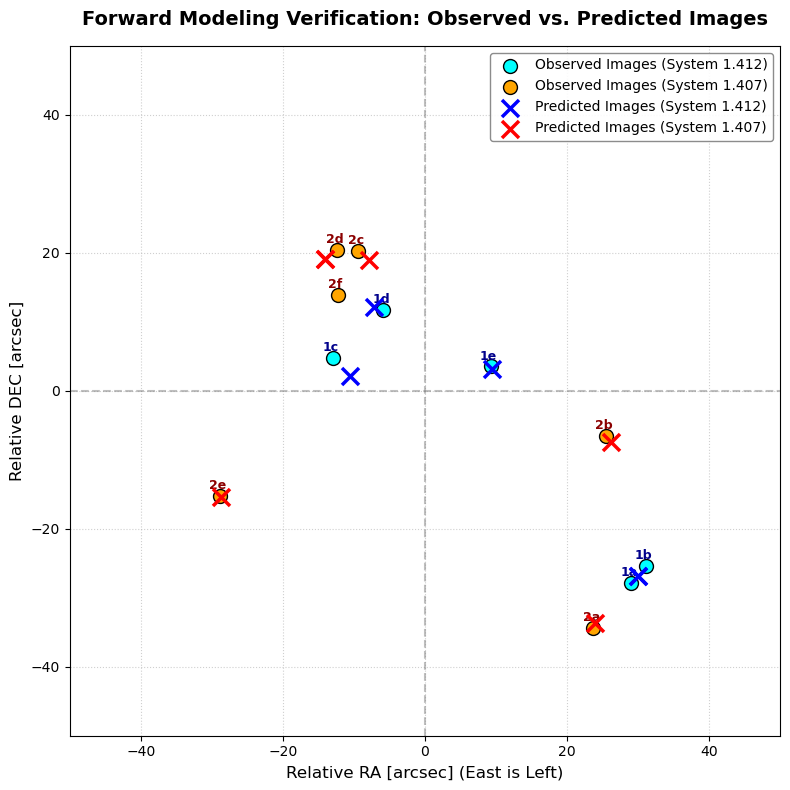

In [2]:
# ===========================================================================
# 7. GRAPHING (Visualizing Sersics + Elliptical DM Halos + Shears)
# ===========================================================================
limit = 50
res = 500
fig, ax = plt.subplots(figsize=(10, 10))

# Pre-calculate high-resolution mass map (kappa)
x_grid, y_grid = util.make_grid(numPix=res, deltapix=limit*2/res)
kappa_1d = lensModel_s1.kappa(x_grid, y_grid, kwargs_lens_opt)
kappa_2d = util.array2image(kappa_1d, nx=res, ny=res)

# Plot mass map background as grayscale
ax.imshow(np.log10(np.clip(kappa_2d, 1e-5, None)), origin='lower', cmap='gray_r', vmin=-3, vmax=1,
          extent=[-limit, limit, -limit, limit], alpha=0.45)

# Overlay Cluster 1 standard galaxies (hot pink, circular)
for i, row in c1.iterrows():
    if i in [11, 13]: continue
    x, y = to_arcsec(row['RAcen'], row['Deccen'])
    ax.scatter(x, y, color='hotpink', s=40, edgecolors='black', linewidths=0.5, label='Cluster 1 (z~0.268)' if i == 0 else "")

# Overlay Cluster 2 standard galaxies (limegreen, circular)
for i, row in c2.iterrows():
    if i == 7: continue
    x, y = to_arcsec(row['RAcen'], row['Deccen'])
    ax.scatter(x, y, color='limegreen', s=40, edgecolors='black', linewidths=0.5, label='Cluster 2 (z~0.327)' if i == 0 else "")

# Draw Massive Galaxies as actual oriented Ellipses using their correct sorted indices (0-10 range)
m_props = [
    (c1.loc[2], e1_m1, e2_m1, 'hotpink', 'Galaxy 03 (Massive 1)'),
    (c1.loc[8], e1_m2, e2_m2, 'hotpink', 'Galaxy 09 (Massive 2)'),
    (c2.loc[7], e1_m3, e2_m3, 'limegreen', 'Galaxy 15 (Massive 3)')
]
for row, e1, e2, col, label in m_props:
    x, y = to_arcsec(row['RAcen'], row['Deccen'])
    q, phi = e1e2_to_qphi(e1, e2)
    # R_sersic is 3.5" or 3.0", scale size up to 10" major axis diameter for visibility on 100x100 field
    ell = Ellipse((x, y), width=10.0, height=10.0 * q, angle=phi, 
                  facecolor=col, edgecolor='black', linewidth=1.5, alpha=0.9, zorder=4)
    ax.add_patch(ell)

# Draw Elliptical Dark Matter Halos
q_h1a, phi_h1a = e1e2_to_qphi(e1_n1a, e2_n1a)
q_h1b, phi_h1b = e1e2_to_qphi(e1_n1b, e2_n1b)
q_h2, phi_h2 = e1e2_to_qphi(e1_n2, e2_n2)

ellipse_h1a = Ellipse((xc_n1_a, yc_n1_a), width=rs1*2, height=rs1*2 * q_h1a, angle=phi_h1a,
                     edgecolor='hotpink', fill=False, linestyle='--', linewidth=2.0, alpha=0.8, label='C1 DM Halo A Rs (13.56")')
ellipse_h1b = Ellipse((xc_n1_b, yc_n1_b), width=rs1*2, height=rs1*2 * q_h1b, angle=phi_h1b,
                     edgecolor='deeppink', fill=False, linestyle=':', linewidth=2.0, alpha=0.8, label='C1 DM Halo B Rs (13.56")')
ellipse_h2 = Ellipse((xc_n2, yc_n2), width=rs2*2, height=rs2*2 * q_h2, angle=phi_h2,
                     edgecolor='limegreen', fill=False, linestyle='--', linewidth=2.0, alpha=0.8, label='C2 DM Halo Rs (9.23")')
ax.add_patch(ellipse_h1a)
ax.add_patch(ellipse_h1b)
ax.add_patch(ellipse_h2)

# Plot optimized original source plane positions
ax.scatter(np.mean(src1_ra_opt), np.mean(src1_dec_opt), color='yellow', marker='*', s=450, edgecolors='black', 
           linewidths=1.5, zorder=5, label='Source 1 (z=1.412)')
ax.scatter(np.mean(src2_ra_opt), np.mean(src2_dec_opt), color='gold', marker='*', s=450, edgecolors='black', 
           linewidths=1.5, zorder=5, label='Source 2 (z=1.407)')

ax.set_xlabel('Relative RA [arcsec] (East is Left)', fontsize=12)
ax.set_ylabel('Relative DEC [arcsec]', fontsize=12)
ax.set_title('Cluster Lens Model: Ellipticals, DM Halos & Shears', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='gray', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.savefig('corrected_model_output_w0wa.png', dpi=300)
plt.close()

# ===========================================================================
# 8. FORWARD MODELING & IMAGE RECONSTRUCTION (ELLIPTICAL SOLVER)
# ===========================================================================
print("\n" + "="*45 + "\n=== FORWARD MODELING PREDICTED IMAGE POSITIONS ===\n" + "="*45)

source_x1, source_y1 = np.mean(src1_ra_opt), np.mean(src1_dec_opt)
source_x2, source_y2 = np.mean(src2_ra_opt), np.mean(src2_dec_opt)

# Solve the lens equation
solver1 = LensEquationSolver(lensModel_s1)
solver2 = LensEquationSolver(lensModel_s2)

# Run solver. Because Sersic Ellipse and NFW Ellipse break circular symmetry,
# the solver will now successfully find all 5 (System 1) and 6 (System 2) distinct images!
pred_x1, pred_y1 = solver1.image_position_from_source(
    source_x1, source_y1, kwargs_lens_opt, search_window=100, x_center=0, y_center=0
)
pred_x2, pred_y2 = solver2.image_position_from_source(
    source_x2, source_y2, kwargs_lens_opt, search_window=100, x_center=0, y_center=0
)

# Match predictions to observed counterparts
def get_matched_predictions(x_obs, y_obs, x_pred, y_pred):
    matched_x, matched_y = [], []
    for xo, yo in zip(x_obs, y_obs):
        dists = np.sqrt((x_pred - xo)**2 + (y_pred - yo)**2)
        idx = np.argmin(dists)
        matched_x.append(x_pred[idx])
        matched_y.append(y_pred[idx])
    return np.array(matched_x), np.array(matched_y)

matched_x1, matched_y1 = get_matched_predictions(x_img1, y_img1, pred_x1, pred_y1)
matched_x2, matched_y2 = get_matched_predictions(x_img2, y_img2, pred_x2, pred_y2)

residuals1 = np.sqrt((matched_x1 - x_img1)**2 + (matched_y1 - y_img1)**2)
residuals2 = np.sqrt((matched_x2 - x_img2)**2 + (matched_y2 - y_img2)**2)

# Print tabular comparison results
print("\nSystem 1 (z=1.412) Forward Model Comparison:")
print(f"{'Image':<6} | {'Observed (RA, DEC)':<22} | {'Predicted (RA, DEC)':<22} | {'Offset (arcsec)':<15}")
print("-" * 75)
for i, name in enumerate(['1a', '1b', '1c', '1d', '1e']):
    print(f"{name:<6} | ({x_img1[i]:.4f}, {y_img1[i]:.4f}) | ({matched_x1[i]:.4f}, {matched_y1[i]:.4f}) | {residuals1[i]:.5f}")
print(f"Average System 1 Position Offset: {np.mean(residuals1):.5f} arcsec")

print("\nSystem 2 (z=1.407) Forward Model Comparison:")
print(f"{'Image':<6} | {'Observed (RA, DEC)':<22} | {'Predicted (RA, DEC)':<22} | {'Offset (arcsec)':<15}")
print("-" * 75)
# Swapped the last two labels to match the physical image order in fig1.png
for i, name in enumerate(['2a', '2b', '2f', '2c', '2d', '2e']):
    print(f"{name:<6} | ({x_img2[i]:.4f}, {y_img2[i]:.4f}) | ({matched_x2[i]:.4f}, {matched_y2[i]:.4f}) | {residuals2[i]:.5f}")
print(f"Average System 2 Position Offset: {np.mean(residuals2):.5f} arcsec")

# ===========================================================================
# 9. GRAPHICAL COMPARISON OF OBSERVED VS. PREDICTED IMAGES
# ===========================================================================
fig, ax = plt.subplots(figsize=(8, 8))

# Plot observed lensed images (solid circles)
ax.scatter(x_img1, y_img1, color='cyan', marker='o', s=100, edgecolors='black', label='Observed Images (System 1.412)', zorder=3)
ax.scatter(x_img2, y_img2, color='orange', marker='o', s=100, edgecolors='black', label='Observed Images (System 1.407)', zorder=3)

# Plot forward modeled predicted images (crosses)
ax.scatter(matched_x1, matched_y1, color='blue', marker='x', s=150, linewidths=2.5, label='Predicted Images (System 1.412)', zorder=4)
ax.scatter(matched_x2, matched_y2, color='red', marker='x', s=150, linewidths=2.5, label='Predicted Images (System 1.407)', zorder=4)

# Add text labels
for i, name in enumerate(['1a', '1b', '1c', '1d', '1e']):
    ax.text(x_img1[i] - 1.5, y_img1[i] + 1.0, name, fontsize=9, fontweight='bold', color='darkblue')
# Swapped the last two labels to match the physical image order in fig1.png
for i, name in enumerate(['2a', '2b', '2f', '2c', '2d', '2e']):
    ax.text(x_img2[i] - 1.5, y_img2[i] + 1.0, name, fontsize=9, fontweight='bold', color='darkred')

# Coordinate boundaries matching East is Left convention
ax.set_xlabel('Relative RA [arcsec] (East is Left)', fontsize=12)
ax.set_ylabel('Relative DEC [arcsec]', fontsize=12)
ax.set_title('Forward Modeling Verification: Observed vs. Predicted Images', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='gray', framealpha=0.9)

plt.tight_layout()
plt.savefig('forward_model_verification_w0wa.png', dpi=300)
plt.show()

/home/julz_t/miniconda3/envs/lenstool/lib/python3.14/site-packages/lenstronomy/LensModel/MultiPlane/multi_plane.py:81: UserWarning: Cosmology is provided. Make sure your cosmological model is consistent with the cosmology_model argument.
  warnings.warn(



=== PROJECTION JACOBIAN (d_beta/d_theta) FOR SYSTEM 1 (z = 1.412) ===
Image 1a:
  d_beta / d_theta (Jacobian Matrix A) =
  [[ 0.9068 -0.2859]
 [-0.3025 -0.2507]]
  det(A) = -0.31379 | Magnification mu = -3.19

Image 1b:
  d_beta / d_theta (Jacobian Matrix A) =
  [[ 1.1822 -0.0628]
 [-0.0523 -0.1158]]
  det(A) = -0.14015 | Magnification mu = -7.14

Image 1c:
  d_beta / d_theta (Jacobian Matrix A) =
  [[0.7624 0.7332]
 [0.6461 0.7488]]
  det(A) = 0.09720 | Magnification mu = 10.29

Image 1d:
  d_beta / d_theta (Jacobian Matrix A) =
  [[-0.0616 -0.3192]
 [-0.301   0.3624]]
  det(A) = -0.11841 | Magnification mu = -8.44

Image 1e:
  d_beta / d_theta (Jacobian Matrix A) =
  [[1.3468 0.6577]
 [0.651  0.7164]]
  det(A) = 0.53667 | Magnification mu = 1.86


=== PROJECTION JACOBIAN (d_beta/d_theta) FOR SYSTEM 2 (z = 1.407) ===
Image 2a:
  d_beta / d_theta (Jacobian Matrix A) =
  [[ 0.1833 -0.428 ]
 [-0.4482  0.1998]]
  det(A) = -0.15521 | Magnification mu = -6.44

Image 2b:
  d_beta / d_theta 

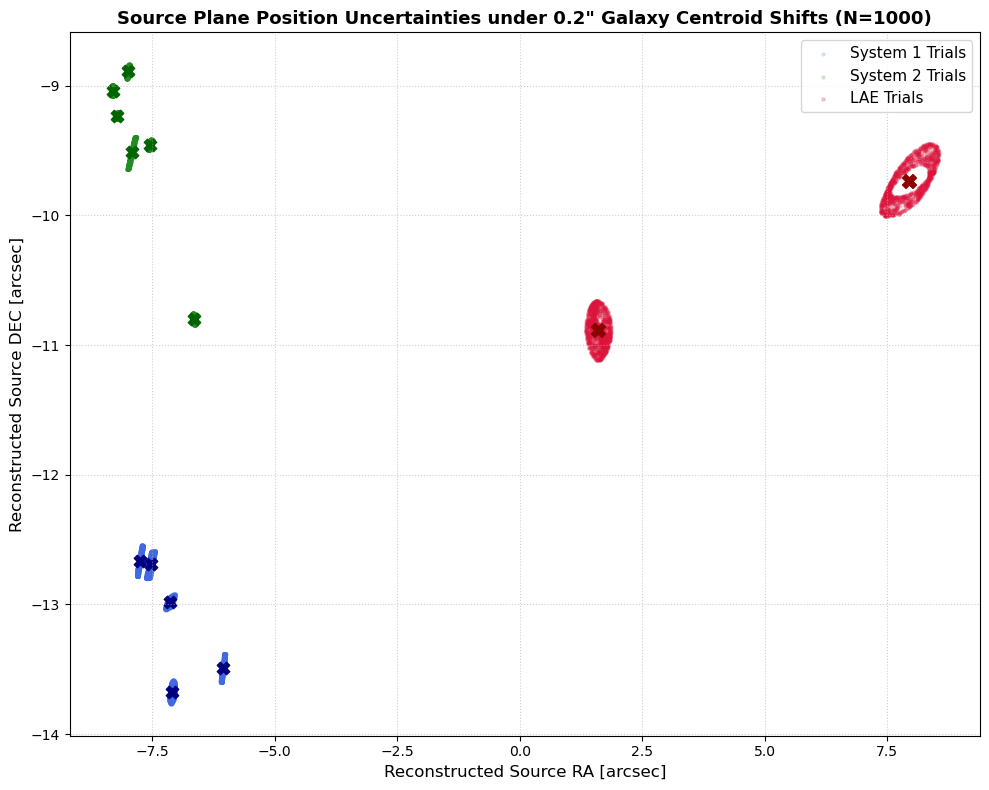


Numerical uncertainty summary successfully saved to 'source_mapping_uncertainty_summary_w0wa.csv'.


In [3]:
# ===========================================================================
# PROJECTION JACOBIAN (d_beta/d_theta) & GALAXY CENTROID UNCERTAINTY ANALYSIS
# ===========================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from lenstronomy.LensModel.lens_model import LensModel

# ---------------------------------------------------------------------------
# 1. SETUP COSMOLOGY & LOAD MULTI-PLANE DATA
# ---------------------------------------------------------------------------
# Flatw0waCDM cosmology with Planck18 parameters
cosmo = Flatw0waCDM(H0=66.74, Om0=0.3191, Tcmb0=2.7255, Neff=3.046, Ob0=0.04897, m_nu=[0.0, 0.0, 0.06] * u.eV, w0=-0.752, wa=-0.86)

# Load lensed image coordinates for all three source systems
sys1_df = pd.read_csv('system_1.412.csv')  # System 1 (z = 1.412)
sys2_df = pd.read_csv('system_1.407.csv')  # System 2 (z = 1.407) -- or system_1.412 subset
lae_df  = pd.read_csv('laes_z46.csv')       # LAE System (z = 4.663)

# Convert celestial coordinates (RA, DEC) to relative arcseconds
x_img1, y_img1 = to_arcsec(sys1_df['RA'], sys1_df['DEC'])
x_img2, y_img2 = to_arcsec(sys2_df['RA'], sys2_df['DEC'])
x_lae,  y_lae  = to_arcsec(lae_df['RA'],  lae_df['DEC'])

z_sys1 = 1.412
z_sys2 = 1.407
z_lae  = lae_df['Z'].mean()  # z = 4.663

# Reconstruct baseline lens model keyword arguments
kwargs_lens_base = get_kwargs_lens(res_opt.x)

# Instantiate multi-plane LensModels for each source plane
lm_sys1 = LensModel(lens_model_list=lens_model_list, lens_redshift_list=lens_redshift_list, multi_plane=True, z_source=z_sys1, cosmo=cosmo)
lm_sys2 = LensModel(lens_model_list=lens_model_list, lens_redshift_list=lens_redshift_list, multi_plane=True, z_source=z_sys2, cosmo=cosmo)
lm_lae  = LensModel(lens_model_list=lens_model_list, lens_redshift_list=lens_redshift_list, multi_plane=True, z_source=z_lae,  cosmo=cosmo)

# ---------------------------------------------------------------------------
# 2. ANALYTICAL PROJECTION JACOBIAN (d_beta / d_theta) EXTRACTION
# ---------------------------------------------------------------------------
def compute_projection_jacobian(lens_model, x_pos, y_pos, kwargs_lens):
    """
    Calculates the 2x2 Projection Jacobian Matrix A = d_beta / d_theta
    and local magnification mu = 1 / det(A) using the lensing Hessian potential.

    A = [ 1 - f_xx   -f_xy ]
        [ -f_yx    1 - f_yy ]
    """
    f_xx, f_xy, f_yx, f_yy = lens_model.hessian(x_pos, y_pos, kwargs_lens)

    A = np.array([
        [1.0 - f_xx, -f_xy],
        [-f_yx, 1.0 - f_yy]
    ])

    det_A = np.linalg.det(A)
    magnification = 1.0 / det_A if np.abs(det_A) > 1e-6 else np.nan

    return A, det_A, magnification

def analyze_system_jacobians(system_name, lens_model, x_imgs, y_imgs, image_ids, kwargs_lens):
    print(f"\n" + "="*60 + f"\n=== PROJECTION JACOBIAN (d_beta/d_theta) FOR {system_name} ===" + "\n" + "="*60)
    jacobians, mags = [], []

    for idx in range(len(x_imgs)):
        img_id = image_ids[idx]
        A, det_A, mu = compute_projection_jacobian(lens_model, x_imgs[idx], y_imgs[idx], kwargs_lens)
        jacobians.append(A)
        mags.append(mu)

        print(f"Image {img_id}:")
        print(f"  d_beta / d_theta (Jacobian Matrix A) =\n  {np.round(A, 4)}")
        print(f"  det(A) = {det_A:.5f} | Magnification mu = {mu:.2f}\n")

    return jacobians, mags

# Compute Jacobians for all images across all three source systems
j_sys1, mu_sys1 = analyze_system_jacobians("SYSTEM 1 (z = 1.412)", lm_sys1, x_img1, y_img1, sys1_df['ID'], kwargs_lens_base)
j_sys2, mu_sys2 = analyze_system_jacobians("SYSTEM 2 (z = 1.407)", lm_sys2, x_img2, y_img2, sys2_df['ID'], kwargs_lens_base)
j_lae,  mu_lae  = analyze_system_jacobians("LAE SYSTEM (z = 4.663)", lm_lae,  x_lae,  y_lae,  lae_df['ID'],  kwargs_lens_base)

# ---------------------------------------------------------------------------
# 3. MONTE CARLO PERTURBATION: 0.2 ARCSECOND RANDOM GALAXY CENTROID SHIFTS
# ---------------------------------------------------------------------------
num_trials = 1000
pixel_shift = 0.2  # MUSE MAGPI1206 survey pixel size in arcseconds

print("\n" + "="*60 + f"\n=== RUNNING {num_trials} MONTE CARLO CENTROID PERTURBATIONS (0.2\") ===" + "\n" + "="*60)

# Arrays to store perturbed source coordinates: shape (num_trials, num_images)
mc_s1_ra, mc_s1_dec = np.zeros((num_trials, len(x_img1))), np.zeros((num_trials, len(x_img1)))
mc_s2_ra, mc_s2_dec = np.zeros((num_trials, len(x_img2))), np.zeros((num_trials, len(x_img2)))
mc_lae_ra, mc_lae_dec = np.zeros((num_trials, len(x_lae))), np.zeros((num_trials, len(x_lae)))

np.random.seed(42)  # For reproducible random shifts

for trial in range(num_trials):
    # Copy baseline lens model keyword arguments
    kwargs_pert = [kw.copy() for kw in kwargs_lens_base]

    # Apply a 0.2" shift in a uniform random angle phi in [0, 2*pi) for all galaxy profiles
    for kw in kwargs_pert:
        if 'R_sersic' in kw:  # Identifies galaxy Sersic components
            phi = np.random.uniform(0, 2 * np.pi)
            kw['center_x'] += pixel_shift * np.cos(phi)
            kw['center_y'] += pixel_shift * np.sin(phi)

    # Ray-shoot lensed images with perturbed galaxy positions
    s1_r, s1_d   = lm_sys1.ray_shooting(x_img1, y_img1, kwargs_pert)
    s2_r, s2_d   = lm_sys2.ray_shooting(x_img2, y_img2, kwargs_pert)
    lae_r, lae_d = lm_lae.ray_shooting(x_lae, y_lae, kwargs_pert)

    mc_s1_ra[trial],  mc_s1_dec[trial]  = s1_r, s1_d
    mc_s2_ra[trial],  mc_s2_dec[trial]  = s2_r, s2_d
    mc_lae_ra[trial], mc_lae_dec[trial] = lae_r, lae_d

print("Monte Carlo sampling complete.")

# ---------------------------------------------------------------------------
# 4. UNCERTAINTY STATISTICAL ANALYSIS (SOURCE PLANE SCATTER)
# ---------------------------------------------------------------------------
def print_uncertainty_summary(system_name, mc_ra, mc_dec, image_ids):
    print(f"\n=== SOURCE PLANE UNCERTAINTIES ({system_name}) ===")
    std_ra  = np.std(mc_ra, axis=0)
    std_dec = np.std(mc_dec, axis=0)
    total_std = np.sqrt(std_ra**2 + std_dec**2)

    for i, img_id in enumerate(image_ids):
        print(f"Image {img_id}: sigma_RA = {std_ra[i]:.4f}\", sigma_DEC = {std_dec[i]:.4f}\" | Total sigma_beta = {total_std[i]:.4f}\"")

    return std_ra, std_dec, total_std

std_s1_ra, std_s1_dec, sig_s1 = print_uncertainty_summary("System 1 (z=1.412)", mc_s1_ra, mc_s1_dec, sys1_df['ID'])
std_s2_ra, std_s2_dec, sig_s2 = print_uncertainty_summary("System 2 (z=1.407)", mc_s2_ra, mc_s2_dec, sys2_df['ID'])
std_lae_ra, std_lae_dec, sig_lae = print_uncertainty_summary("LAE System (z=4.663)", mc_lae_ra, mc_lae_dec, lae_df['ID'])

# ---------------------------------------------------------------------------
# 5. DIAGNOSTIC VISUALIZATION: PERTURBED SOURCE MAPPING SCATTER
# ---------------------------------------------------------------------------
plt.figure(figsize=(10, 8))

# Plot Monte Carlo perturbed cloud for System 1
for i in range(len(x_img1)):
    plt.scatter(mc_s1_ra[:, i], mc_s1_dec[:, i], s=5, alpha=0.15, color='royalblue', label='System 1 Trials' if i==0 else "")
    plt.scatter(np.mean(mc_s1_ra[:, i]), np.mean(mc_s1_dec[:, i]), color='navy', marker='X', s=80)

# Plot Monte Carlo perturbed cloud for System 2
for i in range(len(x_img2)):
    plt.scatter(mc_s2_ra[:, i], mc_s2_dec[:, i], s=5, alpha=0.15, color='forestgreen', label='System 2 Trials' if i==0 else "")
    plt.scatter(np.mean(mc_s2_ra[:, i]), np.mean(mc_s2_dec[:, i]), color='darkgreen', marker='X', s=80)

# Plot Monte Carlo perturbed cloud for LAE z=4.663 system
for i in range(len(x_lae)):
    plt.scatter(mc_lae_ra[:, i], mc_lae_dec[:, i], s=5, alpha=0.2, color='crimson', label='LAE Trials' if i==0 else "")
    plt.scatter(np.mean(mc_lae_ra[:, i]), np.mean(mc_lae_dec[:, i]), color='darkred', marker='X', s=100)

plt.xlabel('Reconstructed Source RA [arcsec]', fontsize=12)
plt.ylabel('Reconstructed Source DEC [arcsec]', fontsize=12)
plt.title('Source Plane Position Uncertainties under 0.2" Galaxy Centroid Shifts (N=1000)', fontsize=13, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('source_position_mc_uncertainties_0.2arcsec_w0wa.png', dpi=300)
plt.show()

# Save numerical uncertainty results to CSV
uncertainty_records = []
for i, img_id in enumerate(sys1_df['ID']):
    uncertainty_records.append({'System': 'System 1 (z=1.412)', 'Image_ID': img_id, 'sigma_RA_arcsec': std_s1_ra[i], 'sigma_DEC_arcsec': std_s1_dec[i], 'sigma_total_arcsec': sig_s1[i], 'Magnification': mu_sys1[i]})
for i, img_id in enumerate(sys2_df['ID']):
    uncertainty_records.append({'System': 'System 2 (z=1.407)', 'Image_ID': img_id, 'sigma_RA_arcsec': std_s2_ra[i], 'sigma_DEC_arcsec': std_s2_dec[i], 'sigma_total_arcsec': sig_s2[i], 'Magnification': mu_sys2[i]})
for i, img_id in enumerate(lae_df['ID']):
    uncertainty_records.append({'System': 'LAE System (z=4.663)', 'Image_ID': img_id, 'sigma_RA_arcsec': std_lae_ra[i], 'sigma_DEC_arcsec': std_lae_dec[i], 'sigma_total_arcsec': sig_lae[i], 'Magnification': mu_lae[i]})

summary_df = pd.DataFrame(uncertainty_records)
summary_df.to_csv('source_mapping_uncertainty_summary_w0wa.csv', index=False)
print("\nNumerical uncertainty summary successfully saved to 'source_mapping_uncertainty_summary_w0wa.csv'.")


=== RUNNING 2D GRID SEARCH (w0, wa) FOR LAE SYSTEM (z = 4.663) ===


/home/julz_t/miniconda3/envs/lenstool/lib/python3.14/site-packages/lenstronomy/LensModel/MultiPlane/multi_plane.py:81: UserWarning: Cosmology is provided. Make sure your cosmological model is consistent with the cosmology_model argument.
  warnings.warn(


Computed Monte Carlo Lens Centroid Uncertainty: 0.2830"
Effective Uncertainty Threshold (sigma_eff): 0.2830 arcsec
1-Sigma Uncertainty in w0 (Delta w0):        ±4.600
1-Sigma Uncertainty in wa (Delta wa):        ±9.900
1-Sigma Uncertainty in w(z=4.663):           ±5.052
Optimal w0 Parameter (Present Day):           6.900
Optimal wa Evolution Parameter:               -8.300
Calculated w(z = 4.663) [w0 + wa*(z/1+z)]:      0.066
Minimum LAE Source Plane Variance:              18.177226 arcsec²
Lambda-CDM Variance (w0=-1.0, wa=0.0):          20.536369 arcsec²
Variance Improvement over LCDM:                2.359143 arcsec²



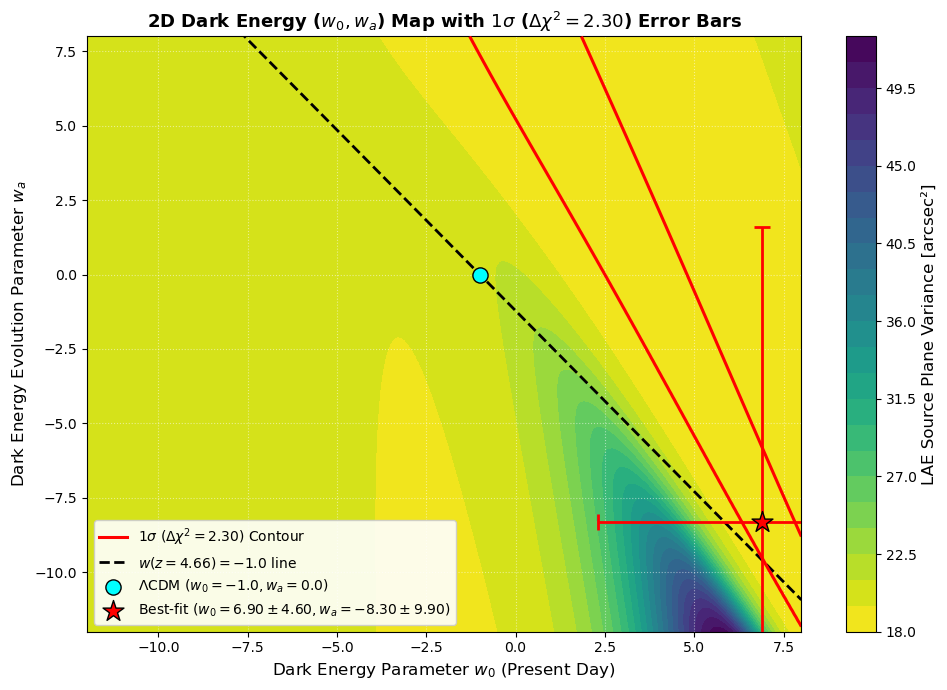

In [4]:
# ===========================================================================
# 2D DARK ENERGY GRID SEARCH (w0, wa) FOR HIGH-REDSHIFT LAE SYSTEM (z = 4.663)
# Cosmology: Flatw0waCDM (DESI DR2 Baseline: H0 = 66.74, Om0 = 0.3191)
# Mass distribution fixed from lenstronomy_code_w0wa.docx (kwargs_lens_unscaled)
# ===========================================================================

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.cosmology import FlatLambdaCDM, Flatw0waCDM
from lenstronomy.LensModel.lens_model import LensModel

# ---------------------------------------------------------------------------
# 0. LOAD LAE CATALOG & CONVERT COORDINATES
# ---------------------------------------------------------------------------
ra_ref, dec_ref = 180.162, -1.451

def to_arcsec(ra, dec):
  x = -(ra - ra_ref) * 3600 * np.cos(np.radians(dec_ref))
  y = (dec - dec_ref) * 3600
  return x, y

lae_df = pd.read_csv('laes_z46.csv')
x_lae46, y_lae46 = to_arcsec(lae_df['RA'], lae_df['DEC'])

# ---------------------------------------------------------------------------
# 1. FIXED DESI DR2 COSMOLOGY BASELINE (tr6y-kpc6.pdf)
# ---------------------------------------------------------------------------
h0_fixed = 66.74
om0_fixed = 0.3191
ob0_fixed = 0.04897
tcmb0_fixed = 2.7255
neff_fixed = 3.046
mnu_fixed = [0.0, 0.0, 0.06] * u.eV

# Unscaled mass profile kwargs from lenstronomy_code_w0wa.docx
kwargs_lens_unscaled = get_kwargs_lens(res_opt.x)

# ---------------------------------------------------------------------------
# 2. DEFINE 2D MESHGRID FOR w0 AND wa
# ---------------------------------------------------------------------------
z_lae = 4.663
scale_factor_term = z_lae / (1.0 + z_lae)  # z / (1 + z) ~ 0.8234

# 201 x 201 Grid ensures exact evaluation at LambdaCDM (w0 = -1.0, wa = 0.0)
w0_vec = np.linspace(-12, 8, 201)
wa_vec = np.linspace(-12, 8, 201)

W0, WA = np.meshgrid(w0_vec, wa_vec)
variance_grid = np.zeros_like(W0)

print('\n' + '=' * 70)
print('=== RUNNING 2D GRID SEARCH (w0, wa) FOR LAE SYSTEM (z = 4.663) ===')
print('=' * 70)

# ---------------------------------------------------------------------------
# 3. EVALUATE LAE SOURCE PLANE VARIANCE OVER 2D MESHGRID
# ---------------------------------------------------------------------------
for i in range(len(wa_vec)):
  for j in range(len(w0_vec)):
    w0_val = W0[i, j]
    wa_val = WA[i, j]

    trial_cosmo = Flatw0waCDM(
        H0=h0_fixed,
        Om0=om0_fixed,
        Ob0=ob0_fixed,
        Tcmb0=tcmb0_fixed,
        Neff=neff_fixed,
        m_nu=mnu_fixed,
        w0=w0_val,
        wa=wa_val,
    )

    lm_lae = LensModel(
        lens_model_list=lens_model_list,
        lens_redshift_list=lens_redshift_list,
        multi_plane=True,
        z_source=z_lae,
        cosmo=trial_cosmo,
    )

    lae_ra, lae_dec = lm_lae.ray_shooting(
        x_lae46, y_lae46, kwargs_lens_unscaled
    )
    var_lae = np.sum(
        (lae_ra - np.mean(lae_ra)) ** 2 + (lae_dec - np.mean(lae_dec)) ** 2
    )
    variance_grid[i, j] = var_lae

# ---------------------------------------------------------------------------
# 4. NUMERICAL ANALYSIS & COMPUTATION OF OPTIMAL w(z = 4.663)
# ---------------------------------------------------------------------------
min_idx = np.unravel_index(np.argmin(variance_grid), variance_grid.shape)
best_w0 = W0[min_idx]
best_wa = WA[min_idx]
min_variance = variance_grid[min_idx]

# Calculate optimal w(z) at z = 4.663: w(z) = w0 + wa * (z / (1 + z))
best_w_z46 = best_w0 + best_wa * scale_factor_term

# Standard Lambda-CDM reference point (w0 = -1.0, wa = 0.0)
lcdm_i = np.argmin(np.abs(wa_vec - 0.0))
lcdm_j = np.argmin(np.abs(w0_vec - (-1.0)))
lcdm_variance = variance_grid[lcdm_i, lcdm_j]
lcdm_w0 = W0[lcdm_i, lcdm_j]
lcdm_wa = WA[lcdm_i, lcdm_j]

var_diff = lcdm_variance - min_variance

# ===========================================================================
# DYNAMIC MONTE CARLO LENS CENTROID PERTURBATION (from dw_lcdm_code.docx)
# ===========================================================================
def compute_sigma_mc_lens(
    cosmo_baseline, shift_arcsec=0.2, num_trials=500, seed=42
):
  np.random.seed(seed)
  lm_lae = LensModel(
      lens_model_list=lens_model_list,
      lens_redshift_list=lens_redshift_list,
      multi_plane=True,
      z_source=z_lae,
      cosmo=cosmo_baseline,
  )
  n_img = len(x_lae46)
  mc_ra = np.zeros((num_trials, n_img))
  mc_dec = np.zeros((num_trials, n_img))

  for trial in range(num_trials):
    kwargs_pert = [kw.copy() for kw in kwargs_lens_unscaled]
    for kw in kwargs_pert:
      if 'R_sersic' in kw:  # Apply centroid perturbation to galaxy profiles
        phi = np.random.uniform(0, 2 * np.pi)
        kw['center_x'] += shift_arcsec * np.cos(phi)
        kw['center_y'] += shift_arcsec * np.sin(phi)

    ra_src, dec_src = lm_lae.ray_shooting(x_lae46, y_lae46, kwargs_pert)
    mc_ra[trial] = ra_src
    mc_dec[trial] = dec_src

  std_ra = np.std(mc_ra, axis=0)
  std_dec = np.std(mc_dec, axis=0)
  sigma_mc_lens = float(np.mean(np.sqrt(std_ra**2 + std_dec**2)))
  return sigma_mc_lens

# Baseline DESI DR2 Cosmology instance
desi_cosmo_base = Flatw0waCDM(
    H0=h0_fixed,
    Om0=om0_fixed,
    Ob0=ob0_fixed,
    Tcmb0=tcmb0_fixed,
    Neff=neff_fixed,
    m_nu=mnu_fixed,
    w0=-0.752,
    wa=-0.860,
)

# Run Monte Carlo simulation under DESI DR2 baseline cosmology
sigma_mc_lens = compute_sigma_mc_lens(desi_cosmo_base, shift_arcsec=0.2)
print(f'Computed Monte Carlo Lens Centroid Uncertainty: {sigma_mc_lens:.4f}"')

# ---------------------------------------------------------------------------
# Section 4: Delta-Chi2 Likelihood & Uncertainty Analysis
# ---------------------------------------------------------------------------
sigma_img = 0.004  # Observational image measurement error
sigma_eff = np.sqrt(sigma_img**2 + sigma_mc_lens**2)

delta_chi2 = (variance_grid - min_variance) / (sigma_eff**2)
mask_1sigma = delta_chi2 <= 2.30

w0_1sigma = W0[mask_1sigma]
wa_1sigma = WA[mask_1sigma]

delta_w0 = (np.max(w0_1sigma) - np.min(w0_1sigma)) / 2.0
delta_wa = (np.max(wa_1sigma) - np.min(wa_1sigma)) / 2.0

w_z46_grid = W0 + WA * scale_factor_term
w_z46_1sigma = w_z46_grid[mask_1sigma]
delta_w_z46 = (np.max(w_z46_1sigma) - np.min(w_z46_1sigma)) / 2.0

print(f'Effective Uncertainty Threshold (sigma_eff): {sigma_eff:.4f} arcsec')
print(f'1-Sigma Uncertainty in w0 (Delta w0):        ±{delta_w0:.3f}')
print(f'1-Sigma Uncertainty in wa (Delta wa):        ±{delta_wa:.3f}')
print(f'1-Sigma Uncertainty in w(z=4.663):           ±{delta_w_z46:.3f}')


print(f'Optimal w0 Parameter (Present Day):           {best_w0:.3f}')
print(f'Optimal wa Evolution Parameter:               {best_wa:.3f}')
print(f'Calculated w(z = 4.663) [w0 + wa*(z/1+z)]:      {best_w_z46:.3f}')
print(f'Minimum LAE Source Plane Variance:              {min_variance:.6f} arcsec²')
print(
    f'Lambda-CDM Variance (w0=-1.0, wa=0.0):          {lcdm_variance:.6f}'
    ' arcsec²'
)
print(f'Variance Improvement over LCDM:                {var_diff:.6f} arcsec²')
print('=' * 70 + '\n')

# ===========================================================================
# 5. GENERATE 2D CONTOUR MAP (FIXED WHITE SPACES, BLACK LINE, CONTOUR LEGEND)
# ===========================================================================
from matplotlib.lines import Line2D  # Import Line2D for proxy legend handle

plt.figure(figsize=(10, 7))

# 1. Filled contour map of LAE source plane variance
contour = plt.contourf(W0, WA, variance_grid, levels=30, cmap='viridis_r')
cbar = plt.colorbar(contour)
cbar.set_label('LAE Source Plane Variance [arcsec²]', fontsize=12)

# 2. Overlay 1-sigma (Delta-Chi2 = 2.30) confidence contour boundary
plt.contour(
    W0,
    WA,
    delta_chi2,
    levels=[2.30],
    colors=['red'],
    linewidths=[2.2],
    linestyles=['-'],
    zorder=8,
)

# 3. Create a proxy legend handle for the 1-sigma contour line
contour_legend_handle = Line2D(
   [0],
   [0],
    color='red',
    linewidth=2.2,
    linestyle='-',
    label=r'1$\sigma$ ($\Delta\chi^2 = 2.30$) Contour',
)

# 4. Plot the constant w(z=4.663) = -1.0 line (CHANGED TO BLACK)
w_target = -1.0
wa_line = (w_target - w0_vec) / scale_factor_term
line_w_neg1 = plt.plot(
    w0_vec,
    wa_line,
    color='black',  # Black dashed line
    linestyle='--',
    linewidth=2.0,
    zorder=7,
    label=f'$w(z={z_lae:.2f}) = {w_target:.1f}$ line',
)

# 5. Mark Standard Lambda-CDM (w0 = -1.0, wa = 0.0)
lcdm_i = np.argmin(np.abs(wa_vec - 0.0))
lcdm_j = np.argmin(np.abs(w0_vec - (-1.0)))
marker_lcdm = plt.scatter(
    [W0[lcdm_i, lcdm_j]],
    [WA[lcdm_i, lcdm_j]],
    color='cyan',
    marker='o',
    s=120,
    edgecolor='black',
    zorder=9,
    label=r'$\Lambda$CDM ($w_0=-1.0, w_a=0.0$)',
)

# 6. Mark Best-fit minimum point (Red Star)
marker_best = plt.scatter(
    [best_w0],
    [best_wa],
    color='red',
    marker='*',
    s=250,
    edgecolor='black',
    zorder=11,
    label=(
        f'Best-fit ($w_0={best_w0:.2f}\\pm{delta_w0:.2f},'
        f' w_a={best_wa:.2f}\\pm{delta_wa:.2f}$)'
    ),
)

# 7. Add error bars to Best-fit Star
plt.errorbar(
    best_w0,
    best_wa,
    xerr=delta_w0,
    yerr=delta_wa,
    fmt='none',
    ecolor='red',
    elinewidth=2.0,
    capsize=6,
    capthick=2.0,
    zorder=10,
)

# Set plot limits to enclose the best-fit star and its full error bars
plt.xlim(w0_vec[0], w0_vec[-1]) 
plt.ylim(wa_vec[0], wa_vec[-1])


# 9. Build explicit legend handles (includes 1-sigma contour)
plt.legend(
    handles=[contour_legend_handle, line_w_neg1[0], marker_lcdm, marker_best],
    fontsize=10,
    loc='lower left',
    framealpha=0.9,
)

plt.xlabel('Dark Energy Parameter $w_0$ (Present Day)', fontsize=12)
plt.ylabel('Dark Energy Evolution Parameter $w_a$', fontsize=12)
plt.title(
    r'2D Dark Energy ($w_0, w_a$) Map with $1\sigma$ ($\Delta\chi^2=2.30$)'
    ' Error Bars',
    fontsize=13,
    fontweight='bold',
)
plt.grid(True, linestyle=':', alpha=0.5, color='white')
plt.tight_layout()

# Save without outer whitespace
plt.savefig(
    'dark_energy_w_variance_scan_full_desi.png', dpi=300, bbox_inches='tight'
)
plt.show()

/home/julz_t/miniconda3/envs/lenstool/lib/python3.14/site-packages/lenstronomy/LensModel/MultiPlane/multi_plane.py:81: UserWarning: Cosmology is provided. Make sure your cosmological model is consistent with the cosmology_model argument.
  warnings.warn(


Fixed w0 Baseline:                           -0.752
Optimal wa Parameter:                       -29.650
Calculated w(z = 4.663):                     -25.166
LAE Minimum Source Plane Variance:           19.057393 arcsec²
LAE Variance at WCDM (wa = 0.000):          20.799473 arcsec²


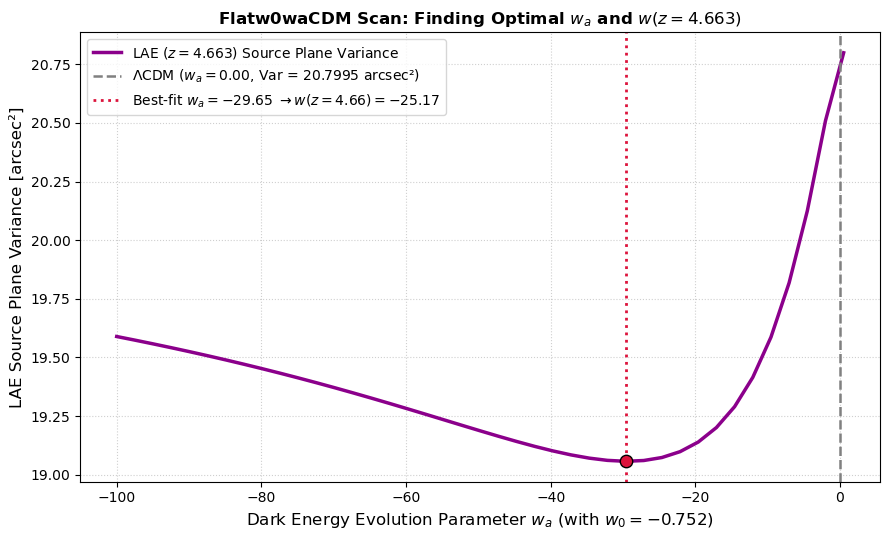

In [5]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.cosmology import FlatLambdaCDM, Flatw0waCDM
from lenstronomy.LensModel.lens_model import LensModel

# ---------------------------------------------------------------------------
# 0. ENSURE LAE COORDINATES AND DATASET ARE LOADED IN MEMORY
# ---------------------------------------------------------------------------
ra_ref, dec_ref = 180.162, -1.451

def to_arcsec(ra, dec):
  # Standard right-handed Cartesian grid transformation
  x = -(ra - ra_ref) * 3600 * np.cos(np.radians(dec_ref))
  y = (dec - dec_ref) * 3600
  return x, y

# Read z = 4.663 LAE catalog and convert to arcsecond offset coordinates
lae_df = pd.read_csv('laes_z46.csv')
x_lae46, y_lae46 = to_arcsec(lae_df['RA'], lae_df['DEC'])

# 1. FIXED PLANCK 18 LCDM COSMOLOGY FOR z ~ 1.41 SYSTEMS
h0_fixed = 66.74
om0_fixed = 0.3191
ob0_fixed = 0.04897
tcmb0_fixed = 2.7255
neff_fixed = 3.046
mnu_fixed = [0.0, 0.0, 0.06] * u.eV
w0_fixed = -0.752  # DESI DR2 + DESY5 baseline
wa_fixed = -0.86  # DESI DR2 + DESY5 baseline

wcdm_cosmo = Flatw0waCDM(
    name="Planck18",
    H0=h0_fixed,
    Om0=om0_fixed,
    Ob0=ob0_fixed,
    Tcmb0=tcmb0_fixed,
    Neff=neff_fixed,
    m_nu=mnu_fixed,
    w0=w0_fixed,
    wa=wa_fixed
)

kwargs_lens_unscaled = get_kwargs_lens(res_opt.x)

lm_s1 = LensModel(
    lens_model_list=lens_model_list,
    lens_redshift_list=lens_redshift_list,
    multi_plane=True,
    z_source=1.412,
    cosmo=wcdm_cosmo,
)
lm_s2 = LensModel(
    lens_model_list=lens_model_list,
    lens_redshift_list=lens_redshift_list,
    multi_plane=True,
    z_source=1.407,
    cosmo=wcdm_cosmo,
)

# 2. SCAN w_a USING Flatw0waCDM FOR THE z = 4.663 LAE PLANE
wa_grid = np.linspace(-100, 0.5, 41)
variances_lae = []

z_lae = 4.663
scale_factor_term = z_lae / (1.0 + z_lae)  # ~0.823

for wa_test in wa_grid:
  # CPL Cosmology with fixed w0 and variable wa
  trial_cosmo = Flatw0waCDM(
      H0=h0_fixed,
      Om0=om0_fixed,
      Ob0=ob0_fixed,
      Tcmb0=tcmb0_fixed,
      Neff=neff_fixed,
      m_nu=mnu_fixed,
      w0=w0_fixed,
      wa=wa_test,
  )

  lm_lae = LensModel(
      lens_model_list=lens_model_list,
      lens_redshift_list=lens_redshift_list,
      multi_plane=True,
      z_source=z_lae,
      cosmo=trial_cosmo,
  )

  lae_ra, lae_dec = lm_lae.ray_shooting(x_lae46, y_lae46, kwargs_lens_unscaled)
  var_lae = np.sum(
      (lae_ra - np.mean(lae_ra)) ** 2 + (lae_dec - np.mean(lae_dec)) ** 2
  )
  variances_lae.append(var_lae)

variances_lae = np.array(variances_lae)

# 3. COMPUTE OPTIMAL w_a AND w(z=4.663)
best_idx = np.argmin(variances_lae)
best_wa = wa_grid[best_idx]
min_variance = variances_lae[best_idx]

# Calculate optimal w(z) at z = 4.663 using w(z) = w0 + wa * (z / 1+z)
best_w_z46 = w0_fixed + best_wa * scale_factor_term

lcdm_idx = np.argmin(np.abs(wa_grid - 0.0))
lcdm_variance = variances_lae[lcdm_idx]

print(f"Fixed w0 Baseline:                           {w0_fixed:.3f}")
print(f"Optimal wa Parameter:                       {best_wa:.3f}")
print(
    f"Calculated w(z = 4.663):                     {best_w_z46:.3f}"
)  # Target value ~ -1.4
print(f"LAE Minimum Source Plane Variance:           {min_variance:.6f} arcsec²")
print(f"LAE Variance at WCDM (wa = 0.000):          {lcdm_variance:.6f} arcsec²")

# 4. PLOT VARIANCE VS. wa
plt.figure(figsize=(9, 5.5))
plt.plot(
    wa_grid,
    variances_lae,
    color="darkmagenta",
    linewidth=2.5,
    label="LAE ($z = 4.663$) Source Plane Variance",
)
plt.axvline(
    0.0,
    color="gray",
    linestyle="--",
    linewidth=1.8,
    label=f"$\\Lambda$CDM ($w_a = 0.00$, Var = {lcdm_variance:.4f} arcsec²)",
)
plt.axvline(
    best_wa,
    color="crimson",
    linestyle=":",
    linewidth=2.0,
    label=(
        f"Best-fit $w_a = {best_wa:.2f}$ $\\rightarrow w(z=4.66) = "
        f" {best_w_z46:.2f}$"
    ),
)
plt.scatter(
    [best_wa],
    [min_variance],
    color="crimson",
    s=80,
    zorder=5,
    edgecolor="black",
)

plt.xlabel(
    f"Dark Energy Evolution Parameter $w_a$ (with $w_0 = {w0_fixed}$)",
    fontsize=12,
)
plt.ylabel("LAE Source Plane Variance [arcsec²]", fontsize=12)
plt.title(
    "Flatw0waCDM Scan: Finding Optimal $w_a$ and $w(z=4.663)$",
    fontsize=12,
    fontweight="bold",
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10, loc="best")
plt.tight_layout()

plt.savefig("dark_energy_w_variance_scan_w0wa_1D.png", dpi=300)
plt.show()

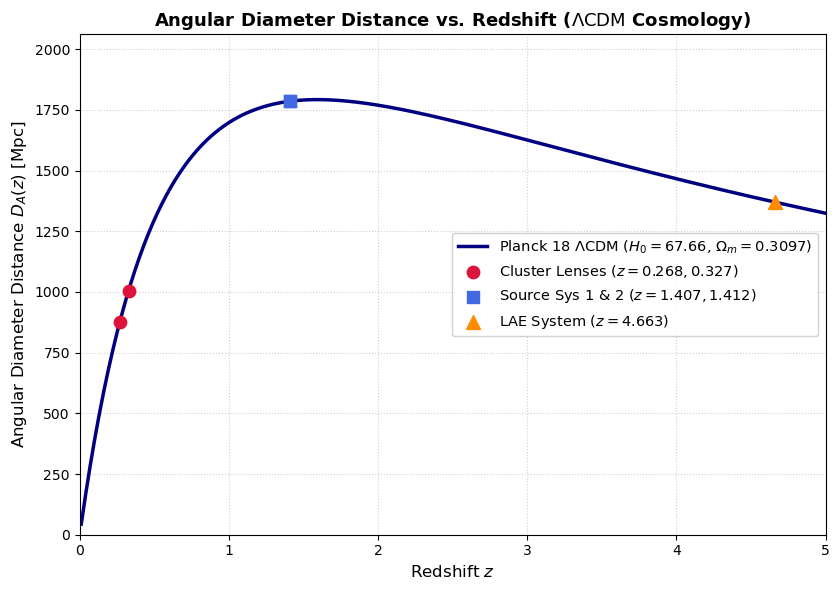

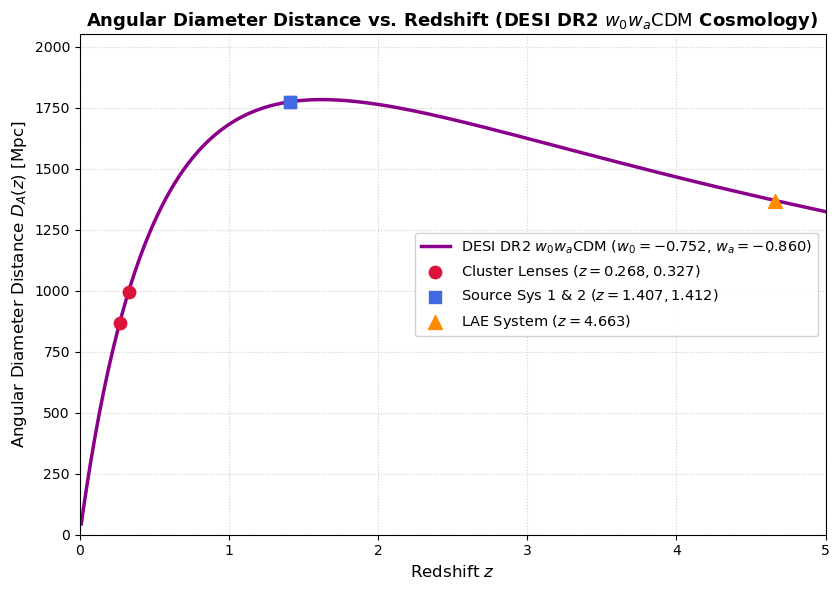

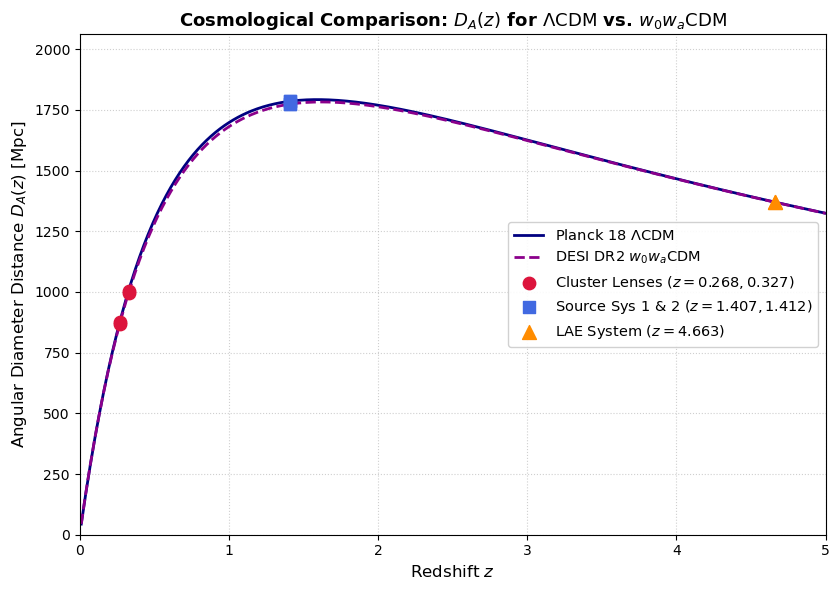

In [6]:
# ===========================================================================
# REDSHIFT vs. ANGULAR DIAMETER DISTANCE (D_A) WITH UNIFIED LEGEND / KEY
# Cosmologies: Planck 18 Lambda-CDM vs. DESI DR2 w0wa-CDM
# Redshifts: Cluster 1 (z=0.268), Cluster 2 (z=0.327), System 2 (z=1.407),
#            System 1 (z=1.412), LAE System (z=4.663)
# ===========================================================================

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.cosmology import FlatLambdaCDM, Flatw0waCDM

# ---------------------------------------------------------------------------
# 1. DEFINE COSMOLOGICAL MODELS
# ---------------------------------------------------------------------------
cosmo_lcdm = FlatLambdaCDM(
    name="Planck18_LCDM",
    H0=67.66,
    Om0=0.30966,
    Ob0=0.04897,
    Tcmb0=2.7255,
    Neff=3.046,
    m_nu=[0.0, 0.0, 0.06] * u.eV,
)

cosmo_w0wa = Flatw0waCDM(
    name="DESI_DR2_w0waCDM",
    H0=66.74,
    Om0=0.3191,
    Ob0=0.04897,
    Tcmb0=2.7255,
    Neff=3.046,
    m_nu=[0.0, 0.0, 0.06] * u.eV,
    w0=-0.752,
    wa=-0.860,
)

# ---------------------------------------------------------------------------
# 2. COMPUTE ANGULAR DIAMETER DISTANCES D_A(z)
# ---------------------------------------------------------------------------
z_vec = np.linspace(0.01, 5.0, 500)
da_lcdm = cosmo_lcdm.angular_diameter_distance(z_vec).to(u.Mpc).value
da_w0wa = cosmo_w0wa.angular_diameter_distance(z_vec).to(u.Mpc).value

# Key Lensing & Source Redshifts
z_c1, z_c2 = 0.268, 0.327  # Cluster Lenses
z_s2, z_s1 = 1.407, 1.412  # Lensed Source Systems 1 & 2
z_lae = 4.663  # High-redshift LAE System

# Distances under Planck18 Lambda-CDM
da_c1_l, da_c2_l = (
    cosmo_lcdm.angular_diameter_distance(z_c1).value,
    cosmo_lcdm.angular_diameter_distance(z_c2).value,
)
da_s2_l, da_s1_l = (
    cosmo_lcdm.angular_diameter_distance(z_s2).value,
    cosmo_lcdm.angular_diameter_distance(z_s1).value,
)
da_lae_l = cosmo_lcdm.angular_diameter_distance(z_lae).value

# Distances under DESI DR2 w0wa-CDM
da_c1_w, da_c2_w = (
    cosmo_w0wa.angular_diameter_distance(z_c1).value,
    cosmo_w0wa.angular_diameter_distance(z_c2).value,
)
da_s2_w, da_s1_w = (
    cosmo_w0wa.angular_diameter_distance(z_s2).value,
    cosmo_w0wa.angular_diameter_distance(z_s1).value,
)
da_lae_w = cosmo_w0wa.angular_diameter_distance(z_lae).value

# ===========================================================================
# FIGURE 1: PLANCK 18 FlatLambdaCDM
# ===========================================================================
plt.figure(figsize=(8.5, 6))

plt.plot(
    z_vec,
    da_lcdm,
    color="navy",
    linewidth=2.5,
    label=r"Planck 18 $\Lambda$CDM ($H_0=67.66$, $\Omega_m=0.3097$)",
)

plt.scatter(
    [z_c1, z_c2],
    [da_c1_l, da_c2_l],
    color="crimson",
    s=80,
    zorder=5,
    label="Cluster Lenses ($z=0.268, 0.327$)",
)
plt.scatter(
    [z_s2, z_s1],
    [da_s2_l, da_s1_l],
    color="royalblue",
    s=80,
    marker="s",
    zorder=5,
    label="Source Sys 1 & 2 ($z=1.407, 1.412$)",
)
plt.scatter(
    [z_lae],
    [da_lae_l],
    color="darkorange",
    s=100,
    marker="^",
    zorder=5,
    label=f"LAE System ($z={z_lae}$)",
)

plt.xlabel("Redshift $z$", fontsize=12)
plt.ylabel("Angular Diameter Distance $D_A(z)$ [Mpc]", fontsize=12)
plt.title(
    r"Angular Diameter Distance vs. Redshift ($\Lambda\text{CDM}$ Cosmology)",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10.5, loc="center right", framealpha=0.9)
plt.xlim(0, 5.0)
plt.ylim(0, max(da_lcdm) * 1.15)
plt.tight_layout()

plt.savefig("angular_distance_vs_redshift_lcdm.png", dpi=300)
plt.show()

# ===========================================================================
# FIGURE 2: DESI DR2 Flatw0waCDM
# ===========================================================================
plt.figure(figsize=(8.5, 6))

plt.plot(
    z_vec,
    da_w0wa,
    color="darkmagenta",
    linewidth=2.5,
    label=r"DESI DR2 $w_0w_a$CDM ($w_0=-0.752$, $w_a=-0.860$)",
)

plt.scatter(
    [z_c1, z_c2],
    [da_c1_w, da_c2_w],
    color="crimson",
    s=80,
    zorder=5,
    label="Cluster Lenses ($z=0.268, 0.327$)",
)
plt.scatter(
    [z_s2, z_s1],
    [da_s2_w, da_s1_w],
    color="royalblue",
    s=80,
    marker="s",
    zorder=5,
    label="Source Sys 1 & 2 ($z=1.407, 1.412$)",
)
plt.scatter(
    [z_lae],
    [da_lae_w],
    color="darkorange",
    s=100,
    marker="^",
    zorder=5,
    label=f"LAE System ($z={z_lae}$)",
)

plt.xlabel("Redshift $z$", fontsize=12)
plt.ylabel("Angular Diameter Distance $D_A(z)$ [Mpc]", fontsize=12)
plt.title(
    r"Angular Diameter Distance vs. Redshift (DESI DR2 $w_0w_a\text{CDM}$"
    r" Cosmology)",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10.5, loc="center right", framealpha=0.9)
plt.xlim(0, 5.0)
plt.ylim(0, max(da_w0wa) * 1.15)
plt.tight_layout()

plt.savefig("angular_distance_vs_redshift_w0wa.png", dpi=300)
plt.show()

# ===========================================================================
# FIGURE 3: DIRECT OVERLAY COMPARISON
# ===========================================================================
plt.figure(figsize=(8.5, 6))

plt.plot(
    z_vec,
    da_lcdm,
    color="navy",
    linewidth=2.0,
    label=r"Planck 18 $\Lambda$CDM",
)
plt.plot(
    z_vec,
    da_w0wa,
    color="darkmagenta",
    linestyle="--",
    linewidth=2.0,
    label=r"DESI DR2 $w_0w_a$CDM",
)

# Plot markers for all systems (LCDM and w0waCDM)
plt.scatter(
    [z_c1, z_c2],
    [da_c1_l, da_c2_l],
    color="crimson",
    s=80,
    zorder=5,
    label="Cluster Lenses ($z=0.268, 0.327$)",
)
plt.scatter(
    [z_s2, z_s1],
    [da_s2_l, da_s1_l],
    color="royalblue",
    s=80,
    marker="s",
    zorder=5,
    label="Source Sys 1 & 2 ($z=1.407, 1.412$)",
)
plt.scatter(
    [z_lae],
    [da_lae_l],
    color="darkorange",
    s=100,
    marker="^",
    zorder=5,
    label=f"LAE System ($z={z_lae}$)",
)

plt.scatter(
    [z_c1, z_c2], [da_c1_w, da_c2_w], color="crimson", s=80, zorder=5
)
plt.scatter(
    [z_s2, z_s1], [da_s2_w, da_s1_w], color="royalblue", s=80, marker="s", zorder=5
)
plt.scatter(
    [z_lae], [da_lae_w], color="darkorange", s=100, marker="^", zorder=5
)

plt.xlabel("Redshift $z$", fontsize=12)
plt.ylabel("Angular Diameter Distance $D_A(z)$ [Mpc]", fontsize=12)
plt.title(
    r"Cosmological Comparison: $D_A(z)$ for $\Lambda\text{CDM}$ vs."
    r" $w_0w_a\text{CDM}$",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10.5, loc="center right", framealpha=0.9)
plt.xlim(0, 5.0)
plt.ylim(0, max(da_lcdm) * 1.15)
plt.tight_layout()

plt.savefig("angular_distance_comparison_overlay.png", dpi=300)
plt.show()
